<a href="https://colab.research.google.com/github/liayejinkwon-arch/INFO-5006-Business-Intelligence/blob/main/Yejin_Kwon_BA_Population_and_Classification_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Business Analyst Population and Analyst-Family Classification Validation

## 1. Setup and Data Loading

The required Python libraries are imported below. Pandas is used for data preparation and comparison, regular expressions are used for title-based classification, and scikit-learn is used to calculate Cohen’s kappa.

### 1.1 Import libraries

In [24]:
import pandas as pd
import numpy as np
import re

from collections import OrderedDict
from sklearn.metrics import cohen_kappa_score
from IPython.display import display

### 1.2 Load the job_posting dataset

Only `job_link` and `job_title` are required for the population and classification validation. Duplicate `job_link` values are removed so that each job posting is represented once.

In [28]:
!pip -q install gdown

import gdown

file_id = "1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT"
posting_file = "/content/linkedin_job_postings_correct.csv"

gdown.download(
    id=file_id,
    output=posting_file,
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT
From (redirected): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT&confirm=t&uuid=d2c8fca1-442e-4cfe-8089-17af2a14300c
To: /content/linkedin_job_postings_correct.csv
100%|██████████| 415M/415M [00:08<00:00, 48.7MB/s]


'/content/linkedin_job_postings_correct.csv'

In [29]:
test = pd.read_csv(posting_file, nrows=5)

print(test.columns.tolist())
print("File path:", posting_file)

['job_link', 'last_processed_time', 'got_summary', 'got_ner', 'is_being_worked', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type']
File path: /content/linkedin_job_postings_correct.csv


In [32]:
import pandas as pd

posting_file = "/content/linkedin_job_postings_correct.csv"

postings = pd.read_csv(
    posting_file,
    usecols=["job_link", "job_title"]
).drop_duplicates(subset="job_link")

print("File used:", posting_file)
print("Job postings loaded:", len(postings))
print("Unique job links:", postings["job_link"].nunique())

display(postings.head())

File used: /content/linkedin_job_postings_correct.csv
Job postings loaded: 1348454
Unique job links: 1348454


,job_link,job_title
0,https://www.linkedin.com/jobs/view/account-exe...,Account Executive - Dispensing (NorCal/Norther...
1,https://www.linkedin.com/jobs/view/registered-...,Registered Nurse - RN Care Manager
2,https://www.linkedin.com/jobs/view/restaurant-...,RESTAURANT SUPERVISOR - THE FORKLIFT
3,https://www.linkedin.com/jobs/view/independent...,Independent Real Estate Agent
4,https://www.linkedin.com/jobs/view/group-unit-...,Group/Unit Supervisor (Systems Support Manager...


## 2. Initial Identification of Business Analyst Job Postings

In [ ]:
ba_titles = titles[
    titles["job_title"].str.contains(
        "business analyst",
        case=False,
        na=False
    )
]

print("BA-related postings:", len(ba_titles))

ba_titles["job_title"].value_counts().head(100)

BA-related postings: 4576


job_title
Business Analyst                                                  1011
Senior Business Analyst                                            211
JDE Business Analyst (Supply Chain)                                163
JD Edwards Business Analyst                                        150
IT Business Analyst                                                 64
                                                                  ... 
IT Business Analyst 2                                                3
Business Analyst (Finance)                                           3
Sr. Business Analyst, Quality Improvement - Quality Management       3
Business Analyst - Finance                                           3
Sr. Business Analyst - Anti-Money Laundering                         3
Name: count, Length: 100, dtype: int64

## 3. Broader Identification of Business Analyst-Related Job Postings

In [ ]:
ba_broad = titles[
    titles["job_title"].str.contains("business", case=False, na=False)
    & titles["job_title"].str.contains("analyst", case=False, na=False)
]

print("Broad BA-related postings:", len(ba_broad))
print("Unique BA-related titles:", ba_broad["job_title"].nunique())

ba_broad["job_title"].value_counts().head(100)

Broad BA-related postings: 6694
Unique BA-related titles: 3171


job_title
Business Analyst                                   1011
Senior Business Analyst                             211
Business Systems Analyst                            179
JDE Business Analyst (Supply Chain)                 163
JD Edwards Business Analyst                         150
                                                   ... 
Business Analyst - #LI-PG1 #Hiring #Omaha #Jobs       5
Junior Business Analyst                               5
Business Operations Analyst- Mid-Level                5
Business Data Analyst II                              5
Agile Business Analyst                                5
Name: count, Length: 100, dtype: int64

## 4. Exploration of Job Level and Specialisation Keywords

In [ ]:
level_keywords = [
    "junior", "jr", "associate",
    "senior", "sr", "lead", "principal"
]

specialisation_keywords = [
    "data", "systems", "system", "IT", "technical",
    "process", "finance", "financial", "supply chain",
    "digital"
]

for word in level_keywords:
    count = ba_broad["job_title"].str.contains(
        rf"\b{word}\b", case=False, na=False, regex=True
    ).sum()
    print(f"{word}: {count}")

print("\n--- Specialisation ---")

for word in specialisation_keywords:
    count = ba_broad["job_title"].str.contains(
        rf"\b{word}\b", case=False, na=False, regex=True
    ).sum()
    print(f"{word}: {count}")

junior: 27
jr: 5
associate: 35
senior: 884
sr: 364
lead: 111
principal: 43

--- Specialisation ---
data: 284
systems: 847
system: 182
IT: 362
technical: 155
process: 140
finance: 89
financial: 137
supply chain: 199
digital: 78


## 5. Comparison of Job Level and Specialisation Coverage

In [ ]:
import re

# Level patterns
level_pattern = r'\b(junior|jr|associate|senior|sr|lead|principal|entry|mid[\s-]?level)\b'

# Potential specialisation patterns
spec_pattern = (
    r'\b(data|systems?|IT|technical|process|finance|financial|'
    r'supply chain|digital|operations?|ERP|JDE|JD Edwards)\b'
)

has_level = ba_broad["job_title"].str.contains(
    level_pattern, case=False, na=False, regex=True
)

has_spec = ba_broad["job_title"].str.contains(
    spec_pattern, case=False, na=False, regex=True
)

print("Total BA-related postings:", len(ba_broad))

print("\n--- Job Level ---")
print("Postings with identifiable level:", has_level.sum())
print("Percentage:", round(has_level.mean() * 100, 2), "%")

print("\n--- Specialisation ---")
print("Postings with identifiable specialisation:", has_spec.sum())
print("Percentage:", round(has_spec.mean() * 100, 2), "%")

Total BA-related postings: 6694

--- Job Level ---
Postings with identifiable level: 1462
Percentage: 21.84 %

--- Specialisation ---
Postings with identifiable specialisation: 2566
Percentage: 38.33 %


/var/folders/bm/4f936v8n11l335mmlcgjds9c0000gn/T/ipykernel_64318/2729304116.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_level = ba_broad["job_title"].str.contains(
/var/folders/bm/4f936v8n11l335mmlcgjds9c0000gn/T/ipykernel_64318/2729304116.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_spec = ba_broad["job_title"].str.contains(


### Interpretation of Job-Level and Specialisation Coverage

**What was done:** BA-related job titles were searched for identifiable job-level terms, such as junior, associate, senior, lead and principal, and for preliminary specialisation terms relating to systems/IT, data, finance, process/operations, supply chain/ERP and digital roles.

**Why it was done:** The initial project direction considered comparing skill demand by job level to support the design of a level-based Business Analyst training framework. Specialisation coverage was also explored as a possible alternative grouping approach.

**Result:** Only 1,462 of 6,694 BA-related postings contained an identifiable job-level term, representing 21.84% of the selected postings. Preliminary specialisation terms were identifiable in 2,566 postings, representing 38.33%.

**Interpretation:** Job level could not be determined from the title for approximately 78.16% of the BA-related postings. The identifiable level terms were also strongly concentrated in senior-level titles. A job-level comparison would therefore rely on incomplete and imbalanced groups. Specialisation produced better coverage but still left most postings without an identifiable category, and some specialisation keywords could overlap.

**Influence on the project:** These results indicated that neither job level nor the initial specialisation keywords provided a sufficiently complete and stable basis for the proposed comparison. This finding motivated further exploration of broader analyst job families.

## 6. Preliminary Specialisation Classification

In [ ]:
spec_groups = {
    "Systems/IT": r'\b(systems?|IT|technical)\b',
    "Data": r'\b(data|analytics?)\b',
    "Finance": r'\b(finance|financial)\b',
    "Process/Operations": r'\b(process|operations?)\b',
    "Supply Chain/ERP": r'\b(supply chain|ERP|JDE|JD Edwards)\b',
    "Digital": r'\bdigital\b'
}

for group, pattern in spec_groups.items():
    count = ba_broad["job_title"].str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    ).sum()

    print(f"{group}: {count}")

Systems/IT: 1445
Data: 332
Finance: 220
Process/Operations: 271
Supply Chain/ERP: 453
Digital: 78


/var/folders/bm/4f936v8n11l335mmlcgjds9c0000gn/T/ipykernel_64318/2861432311.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  count = ba_broad["job_title"].str.contains(


## 7. Inspection of Job Titles within Specialisation Groups

In [ ]:
for group, pattern in spec_groups.items():
    print(f"\n===== {group} =====")

    matches = ba_broad[
        ba_broad["job_title"].str.contains(
            pattern,
            case=False,
            na=False,
            regex=True
        )
    ]

    print(matches["job_title"].value_counts().head(15))


===== Systems/IT =====
job_title
Business Systems Analyst                                179
IT Business Analyst                                      64
Business System Analyst                                  62
Technical Business Analyst                               60
Senior Business Systems Analyst                          41
IT Business Systems Analyst                              18
Internal Controls Analyst (Business and IT)              18
Business Systems Analyst - Digital Experience            16
Sr. Business Systems Analyst                             15
Senior Business Systems Analyst - Digital Experience     14
Senior Business System Analyst                           14
Senior IT Business Analyst                               11
Business Systems Analyst II                              10
Business Systems Analyst - Sr                             8
Junior Business Systems Analyst                           8
Name: count, dtype: int64

===== Data =====
job_title
Business Dat

/var/folders/bm/4f936v8n11l335mmlcgjds9c0000gn/T/ipykernel_64318/387186523.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ba_broad["job_title"].str.contains(


### Influence on the Final Analytic Plan

**What was done:** The most frequent job titles captured by each preliminary specialisation rule were inspected to assess whether the proposed groups were coherent and suitable for comparison.

**Why it was done:** Keyword counts alone do not show whether a group represents a consistent occupation. Reviewing the underlying titles was necessary to identify overlapping concepts, ambiguous classifications and groups dominated by particular title variants.

**Result:** Systems/IT was the largest preliminary specialisation group, while the other groups were smaller and unevenly represented. The title inspection also showed that the preliminary categories mixed Business Analyst specialisations with other adjacent analyst occupations and that some titles could reasonably belong to more than one group.

**Interpretation:** The preliminary specialisation groups were useful for brainstorming but were not sufficiently mutually exclusive or comprehensive for the final comparison. A broader analyst-family framework with one primary family per posting and an explicit Other Analyst category offered a more transparent analytical structure.

**Influence on the final analytic plan:** The project initially considered designing a job-level Business Analyst training framework. I presented the low job-level coverage and the limitations of the preliminary specialisation groups during the group discussion. Based on this evidence, the group agreed to revise the scope toward identifying core Business Analyst skills and comparing them with sufficiently represented adjacent analyst families. The final business need and RQ1/RQ2 were group decisions; my contribution was to provide the preliminary feasibility evidence and document the agreed scope and research-question wording.

## 8. Validation of the Business Analyst Reference Population and Analyst-Family Rules

### 8.1 Preparation of the Validation Dataset

In [13]:
import pandas as pd
import re
from collections import OrderedDict

posting_file = "/content/linkedin_job_postings.csv"
skills_file = "/content/job_skills.csv"

print("Setup complete")

Setup complete


In [14]:
!pip -q install gdown

import gdown

file_id = "18ERAyh_aWO3f0LhqaJm7bsH7MEvM2LR1"
posting_file = "/content/linkedin_job_postings.csv"

gdown.download(
    id=file_id,
    output=posting_file,
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=18ERAyh_aWO3f0LhqaJm7bsH7MEvM2LR1
From (redirected): https://drive.google.com/uc?id=18ERAyh_aWO3f0LhqaJm7bsH7MEvM2LR1&confirm=t&uuid=3ff76c13-e107-4284-b26c-1ce7c1979940
To: /content/linkedin_job_postings.csv
100%|██████████| 673M/673M [00:12<00:00, 56.0MB/s]


'/content/linkedin_job_postings.csv'

In [ ]:
import gdown

correct_file_id = "1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT"
posting_file = "/content/linkedin_job_postings_correct.csv"

gdown.download(
    id=correct_file_id,
    output=posting_file,
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT
From (redirected): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT&confirm=t&uuid=faccfe03-4f05-45e0-b917-cb6ecade70bc
To: /content/linkedin_job_postings_correct.csv
100%|██████████| 415M/415M [00:07<00:00, 56.7MB/s]


'/content/linkedin_job_postings_correct.csv'

In [ ]:
import os
import pandas as pd

print("File exists:", os.path.exists(posting_file))
print("File size:", os.path.getsize(posting_file))

columns = pd.read_csv(posting_file, nrows=0).columns.tolist()
print("Columns:", columns)

File exists: True
File size: 415328702
Columns: ['job_link', 'last_processed_time', 'got_summary', 'got_ner', 'is_being_worked', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type']


In [ ]:
postings = pd.read_csv(
    posting_file,
    usecols=["job_link", "job_title"]
).drop_duplicates("job_link")

print("Postings loaded:", len(postings))

Postings loaded: 1348454


In [ ]:
postings = pd.read_csv(
    posting_file,
    usecols=["job_link", "job_title"]
).drop_duplicates("job_link")

strict_ba = postings[
    postings["job_title"].str.contains(
        r"\bbusiness\s+analysts?\b",
        case=False,
        na=False,
        regex=True
    )
].copy()

print("Complete-word BA population:", len(strict_ba))
print("Unique BA job links:", strict_ba["job_link"].nunique())

Complete-word BA population: 4567
Unique BA job links: 4567


In [ ]:
postings["title_clean"] = (
    postings["job_title"]
    .fillna("")
    .str.strip()
    .str.lower()
)

postings["business_analyst_flag"] = (
    postings["title_clean"].str.contains(
        r"\bbusiness\s+analysts?\b",
        regex=True,
        na=False
    )
)

display(
    postings[
        ["job_link", "job_title", "title_clean", "business_analyst_flag"]
    ].head()
)

,job_link,job_title,title_clean,business_analyst_flag
0,https://www.linkedin.com/jobs/view/account-exe...,Account Executive - Dispensing (NorCal/Norther...,account executive - dispensing (norcal/norther...,False
1,https://www.linkedin.com/jobs/view/registered-...,Registered Nurse - RN Care Manager,registered nurse - rn care manager,False
2,https://www.linkedin.com/jobs/view/restaurant-...,RESTAURANT SUPERVISOR - THE FORKLIFT,restaurant supervisor - the forklift,False
3,https://www.linkedin.com/jobs/view/independent...,Independent Real Estate Agent,independent real estate agent,False
4,https://www.linkedin.com/jobs/view/group-unit-...,Group/Unit Supervisor (Systems Support Manager...,group/unit supervisor (systems support manager...,False


The construction of `title_clean` and `business_analyst_flag` provides reproducible evidence for the derived-variable definitions reported in my individual Data Dictionary.

### 8.2 Application of the Group Analyst-Family Rules

In [ ]:
import re
from collections import OrderedDict

analyst_jobs = postings[
    postings["job_title"].str.contains(
        r"\banalysts?\b",
        case=False,
        na=False,
        regex=True
    )
].copy()

analyst_jobs["title_clean"] = (
    analyst_jobs["job_title"]
    .fillna("")
    .str.strip()
    .str.lower()
)

FAMILY_PATTERNS = OrderedDict({
    "Business Analyst": r"\bbusiness\s+analysts?\b",
    "Business Intelligence Analyst": r"\bbusiness\s+intelligence\s+analysts?\b|\bbi\s+analysts?\b",
    "Data Analyst": r"\bdata\s+analysts?\b|\banalytics\s+analysts?\b",
    "Finance Analyst": r"\bfinancial\s+analysts?\b|\bfinance\s+analysts?\b|\bfp&a\s+analysts?\b|\bbudget\s+analysts?\b|\btreasury\s+analysts?\b|\btax\s+analysts?\b",
    "Systems Analyst": r"\bsystems?\s+analysts?\b|\bbusiness\s+systems?\s+analysts?\b|\bcomputer\s+systems?\s+analysts?\b",
    "Security Analyst": r"\binformation\s+security\s+analysts?\b|\bcyber\s*security\s+analysts?\b|\bcybersecurity\s+analysts?\b|\bsecurity\s+analysts?\b",
    "Operations Analyst": r"\boperations?\s+analysts?\b|\boperational\s+analysts?\b",
    "Program / Project Analyst": r"\bprogram\s+analysts?\b|\bproject\s+analysts?\b",
    "Intelligence Analyst": r"\bintelligence\s+analysts?\b",
    "Research Analyst": r"\bresearch\s+analysts?\b",
    "Risk / Fraud Analyst": r"\brisk\s+analysts?\b|\bfraud\s+analysts?\b",
    "Quality Analyst": r"\bquality\s+analysts?\b|\bqa\s+analysts?\b",
    "Supply Chain Analyst": r"\bsupply\s+chain\s+analysts?\b|\blogistics\s+analysts?\b",
    "Pricing Analyst": r"\bpricing\s+analysts?\b",
    "Marketing Analyst": r"\bmarketing\s+analysts?\b|\bmarket\s+analysts?\b",
    "Behavior Analyst (Excluded)": r"\bbehavio[u]?r\s+analysts?\b"
})

def classify_family(title):
    for family, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, str(title), flags=re.IGNORECASE):
            return family
    return "Other Analyst"

analyst_jobs["analyst_family"] = (
    analyst_jobs["title_clean"].apply(classify_family)
)

print(analyst_jobs["analyst_family"].value_counts())

analyst_family
Other Analyst                    16386
Business Analyst                  4567
Finance Analyst                   3995
Data Analyst                      1943
Systems Analyst                   1918
Program / Project Analyst         1317
Operations Analyst                 901
Security Analyst                   894
Intelligence Analyst               709
Behavior Analyst (Excluded)        698
Research Analyst                   608
Risk / Fraud Analyst               444
Quality Analyst                    364
Business Intelligence Analyst      323
Pricing Analyst                    316
Supply Chain Analyst               298
Marketing Analyst                  144
Name: count, dtype: int64


The `analyst_family` variable was constructed by applying the group’s ordered title-classification rules. These rules were originally developed in Pratik Dhumal’s streamlined group exploration and were reproduced here for my assigned validation work.

### 8.3 Reconciliation of the Business Analyst Populations

In [ ]:
# Preliminary RQ1 substring population
rq1_ba = postings[
    postings["job_title"].str.contains(
        "business analyst",
        case=False,
        na=False,
        regex=False
    )
].copy()

# BA population produced by the group family rule
ba_family = analyst_jobs[
    analyst_jobs["analyst_family"] == "Business Analyst"
].copy()

rq1_links = set(rq1_ba["job_link"])
family_links = set(ba_family["job_link"])

rq1_only_links = rq1_links - family_links
family_only_links = family_links - rq1_links

print("RQ1 substring BA:", len(rq1_links))
print("BA family:", len(family_links))
print("RQ1 only:", len(rq1_only_links))
print("Family only:", len(family_only_links))

print("\nRQ1-only records")
display(
    postings.loc[
        postings["job_link"].isin(rq1_only_links),
        ["job_link", "job_title"]
    ]
)

print("\nFamily-only records")
display(
    postings.loc[
        postings["job_link"].isin(family_only_links),
        ["job_link", "job_title"]
    ]
)

RQ1 substring BA: 4576
BA family: 4567
RQ1 only: 11
Family only: 2

RQ1-only records


,job_link,job_title
8347,https://www.linkedin.com/jobs/view/quality-bus...,"Quality Business Analyst_ North Hollywood, CA ..."
103265,https://www.linkedin.com/jobs/view/business-an...,Business Analyste H/F
322685,https://www.linkedin.com/jobs/view/it-crm-busi...,IT/CRM Business AnalystV
462781,https://www.linkedin.com/jobs/view/senior-busi...,Senior Business Analyst_PN
720792,https://www.linkedin.com/jobs/view/business-an...,Business Analyst_Treasury (Enterprise FinTech ...
720848,https://www.linkedin.com/jobs/view/senior-busi...,"Senior, Business Analyst_Hybrid"
761251,https://www.linkedin.com/jobs/view/business-an...,Business Analyst_ARCA
766366,https://www.linkedin.com/jobs/view/sr-pricing-...,Sr. Pricing Systems Business Analyst_hybrid_Gr...
811808,https://www.linkedin.com/jobs/view/business-an...,Business Analyste (F/H)
969583,https://au.linkedin.com/jobs/view/ict-business...,ICT Business Analyst_Syd



Family-only records


,job_link,job_title
548203,https://www.linkedin.com/jobs/view/business%C2...,Business Analyst (BA)
612293,https://www.linkedin.com/jobs/view/business%C2...,Business Analyst With Salesforce(RFP)


**Interpretation:** The net difference of nine postings did not represent nine directly excluded records. Record-level comparison identified 11 substring-only records and two family-only records. The substring-only records primarily contained suffixes or punctuation attached to the word “Analyst”, while the family-only records contained non-standard whitespace. The complete-word rule was therefore selected as the more reproducible Business Analyst reference definition.

### 8.4 Review of Excluded Behavior Analyst Roles

In [ ]:
behavior_jobs = analyst_jobs[
    analyst_jobs["analyst_family"] == "Behavior Analyst (Excluded)"
]

print("Excluded Behavior Analyst jobs:", len(behavior_jobs))

display(
    behavior_jobs["job_title"]
    .value_counts()
    .head(20)
    .to_frame("Jobs")
)

Excluded Behavior Analyst jobs: 698


,Jobs
job_title,
Board Certified Behavior Analyst,177
Board Certified Behavior Analyst (BCBA),65
Behavior Analyst (BCBA),43
Residency Board Certified Behavior Analyst,28
Behavior Analyst,26
BCBA - Board Certified Behavior Analyst,18
Behavior Consultant (BC)/Board Certified Behavior Analyst (BCBA),13
Board Certified Behavior Analyst (BCBA) In Home,11
Behavior Supervisor | BCBA | Board Certified Behavior Analyst,11


**Interpretation:** A total of 698 Behavior Analyst postings were identified. The most frequent titles referred to Board Certified Behavior Analyst and related clinical roles. These postings represent a different professional domain and were therefore appropriately excluded from the formal business and technology analyst comparison.

### 8.5 Analyst-Family Distribution and Sample-Size Review

In [ ]:
family_counts = analyst_jobs["analyst_family"].value_counts()
display(family_counts.to_frame("Jobs"))

,Jobs
analyst_family,
Other Analyst,16386
Business Analyst,4567
Finance Analyst,3995
Data Analyst,1943
Systems Analyst,1918
Program / Project Analyst,1317
Operations Analyst,901
Security Analyst,894
Intelligence Analyst,709


**Interpretation:** Most named analyst families exceeded the preliminary minimum of 200 postings. Marketing Analyst contained only 144 postings and was therefore not selected for formal RQ2 comparison. Family sizes remain unequal, so within-family percentages should be used instead of raw counts when comparing skill demand.

### 8.6 Multiple-Rule Match Check

In [ ]:
def find_all_family_matches(title):
    matches = []

    for family, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, str(title), flags=re.IGNORECASE):
            matches.append(family)

    return matches

analyst_jobs["matched_families"] = (
    analyst_jobs["title_clean"].apply(find_all_family_matches)
)

analyst_jobs["number_of_matches"] = (
    analyst_jobs["matched_families"].apply(len)
)

multiple_matches = analyst_jobs[
    analyst_jobs["number_of_matches"] > 1
].copy()

print("Jobs matching multiple family rules:", len(multiple_matches))
print(
    "Percentage of analyst jobs:",
    round(len(multiple_matches) / len(analyst_jobs) * 100, 2),
    "%"
)

display(
    multiple_matches[
        ["job_link", "job_title", "analyst_family", "matched_families"]
    ].head(30)
)

Jobs matching multiple family rules: 276
Percentage of analyst jobs: 0.77 %


,job_link,job_title,analyst_family,matched_families
5495,https://www.linkedin.com/jobs/view/data-visual...,Data Visualization / Business Intelligence Ana...,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
18507,https://www.linkedin.com/jobs/view/arpa-h-stat...,ARPA-H STATS Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
24305,https://www.linkedin.com/jobs/view/data-analys...,Data Analyst II/Market Research Analyst,Data Analyst,"[Data Analyst, Research Analyst]"
30959,https://www.linkedin.com/jobs/view/business-in...,Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
38015,https://www.linkedin.com/jobs/view/senior-busi...,Senior Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
47001,https://www.linkedin.com/jobs/view/senior-it-b...,Senior IT Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
73664,https://www.linkedin.com/jobs/view/senior-asso...,Senior Associate Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
74465,https://ca.linkedin.com/jobs/view/business-int...,Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
84787,https://www.linkedin.com/jobs/view/business-in...,Business Intelligence Analyst with Security Cl...,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."
87352,https://www.linkedin.com/jobs/view/business-in...,Business Intelligence Analyst,Business Intelligence Analyst,"[Business Intelligence Analyst, Intelligence A..."


**Interpretation:** A total of 276 postings, or 0.77% of the broad analyst population, matched more than one family rule. Because the classification assigns the first matching family, the order of the rules can influence the final category for these records. These cases should therefore be recognised as a classification limitation and reviewed where they materially affect selected families.

### 8.7 Other Analyst Coverage Review

In [ ]:
other_jobs = analyst_jobs[
    analyst_jobs["analyst_family"] == "Other Analyst"
]

other_percentage = len(other_jobs) / len(analyst_jobs) * 100

print("Other Analyst jobs:", len(other_jobs))
print("Other Analyst percentage:", round(other_percentage, 2), "%")

display(
    other_jobs["title_clean"]
    .value_counts()
    .head(20)
    .to_frame("Jobs")
)

Other Analyst jobs: 16386
Other Analyst percentage: 45.74 %


,Jobs
title_clean,
35g imagery analyst,73
senior analyst,73
payroll analyst,69
compensation analyst,62
inventory analyst,60
billing analyst,57
compliance analyst,56
procurement analyst,56
"senior analyst (bangkok-based, relocation provided)",56


**Interpretation:** Other Analyst contained 16,386 postings, representing 45.74% of the broad analyst population. Frequent unclassified titles included payroll, compensation, inventory, billing, compliance and procurement analyst roles. The large residual category shows that the taxonomy is intentionally selective and should not be interpreted as a comprehensive classification of every analyst occupation.

### 8.8 Validation Summary

In [ ]:
validation_summary = pd.DataFrame({
    "Quality issue": [
        "RQ1 substring BA population",
        "Complete-word BA population",
        "RQ1-only records",
        "Family-only records",
        "Excluded Behavior Analyst records",
        "Multiple-rule matches",
        "Other Analyst records",
        "Other Analyst proportion"
    ],
    "Result": [
        len(rq1_links),
        len(family_links),
        len(rq1_only_links),
        len(family_only_links),
        len(behavior_jobs),
        len(multiple_matches),
        len(other_jobs),
        f"{other_percentage:.2f}%"
    ]
})

display(validation_summary)

,Quality issue,Result
0,RQ1 substring BA population,4576
1,Complete-word BA population,4567
2,RQ1-only records,11
3,Family-only records,2
4,Excluded Behavior Analyst records,698
5,Multiple-rule matches,276
6,Other Analyst records,16386
7,Other Analyst proportion,45.74%


### 8.9 Validation Conclusion

The validation reconciled the two preliminary Business Analyst population definitions and identified the exact records responsible for their difference. The complete-word rule provides a more consistent reference definition for use across RQ1 and RQ2.

The review also confirmed the exclusion of Behavior Analyst roles, quantified multiple-rule matches and assessed the coverage of the analyst-family taxonomy. Although the named families support the proposed cross-family analysis, classification remains title-based and a substantial Other Analyst category remains. These limitations should be considered when interpreting the final skill comparisons.

## 9. Final Outputs and Supporting Visualisations

This section generates the final analyst-family distribution figure and supporting outputs used in the group report.

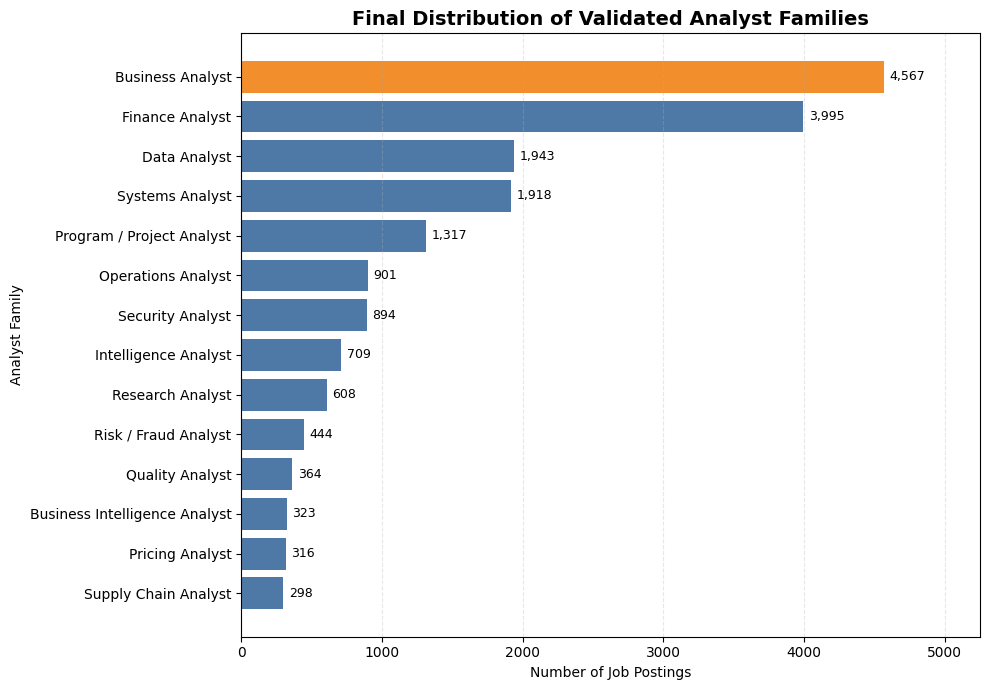

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

family_counts = pd.Series({
    "Business Analyst": 4567,
    "Finance Analyst": 3995,
    "Data Analyst": 1943,
    "Systems Analyst": 1918,
    "Program / Project Analyst": 1317,
    "Operations Analyst": 901,
    "Security Analyst": 894,
    "Intelligence Analyst": 709,
    "Research Analyst": 608,
    "Risk / Fraud Analyst": 444,
    "Quality Analyst": 364,
    "Business Intelligence Analyst": 323,
    "Pricing Analyst": 316,
    "Supply Chain Analyst": 298
}).sort_values()

plt.figure(figsize=(10, 7))

colors = [
    "#F28E2B" if family == "Business Analyst" else "#4E79A7"
    for family in family_counts.index
]

bars = plt.barh(
    family_counts.index,
    family_counts.values,
    color=colors
)

plt.title(
    "Final Distribution of Validated Analyst Families",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Job Postings")
plt.ylabel("Analyst Family")

for bar, value in zip(bars, family_counts.values):
    plt.text(
        value + 40,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=9
    )

plt.xlim(0, family_counts.max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/final_analyst_family_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
!pip -q install gdown

import gdown
import pandas as pd
import re
from collections import OrderedDict

file_id = "1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT"
posting_file = "/content/linkedin_job_postings_correct.csv"

gdown.download(
    id=file_id,
    output=posting_file,
    quiet=False
)

print("Posting file downloaded:", posting_file)

Downloading...
From (original): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT
From (redirected): https://drive.google.com/uc?id=1fQ6WVoJA2IW3K9PU_M7ruhZLHDcQ9htT&confirm=t&uuid=81f92019-ca77-4f7d-9d3c-f1369ade9ec8
To: /content/linkedin_job_postings_correct.csv
100%|██████████| 415M/415M [00:19<00:00, 21.6MB/s]

Posting file downloaded: /content/linkedin_job_postings_correct.csv


In [ ]:
import pandas as pd

RANDOM_SEED = 20261115
selected_links = set()
sample_parts = []

def add_sample(data, n, stratum):
    available = data[
        ~data["job_link"].isin(selected_links)
    ].drop_duplicates("job_link")

    selected = available.sample(
        n=min(n, len(available)),
        random_state=RANDOM_SEED
    ).copy()

    selected["sample_stratum"] = stratum
    selected_links.update(selected["job_link"])
    sample_parts.append(selected)


# 1. Major named families: 5 titles from each family
major_families = [
    "Business Analyst",
    "Finance Analyst",
    "Data Analyst",
    "Systems Analyst",
    "Program / Project Analyst",
    "Operations Analyst"
]

for family in major_families:
    add_sample(
        analyst_jobs[
            analyst_jobs["analyst_family"] == family
        ],
        5,
        family
    )


# 2. Other Analyst: 15 titles
add_sample(
    analyst_jobs[
        analyst_jobs["analyst_family"] == "Other Analyst"
    ],
    15,
    "Other Analyst"
)


# 3. Multiple-rule matches: 10 titles
add_sample(
    multiple_matches,
    10,
    "Multiple-rule match"
)


# 4. Excluded Behavior Analyst: 5 titles
add_sample(
    analyst_jobs[
        analyst_jobs["analyst_family"]
        == "Behavior Analyst (Excluded)"
    ],
    5,
    "Behavior Analyst (Excluded)"
)


# Combine and shuffle the 60 records
validation_sample = pd.concat(
    sample_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=RANDOM_SEED
).reset_index(drop=True)

validation_sample.insert(
    0,
    "sample_id",
    range(1, len(validation_sample) + 1)
)


# File for Lyara: do not reveal the existing model classification
lyara_sample = validation_sample[
    ["sample_id", "job_title"]
].copy()

lyara_sample["lyara_label"] = ""
lyara_sample["comments"] = ""

lyara_sample.to_csv(
    "/content/lyara_title_validation_sample.csv",
    index=False
)


# File for Yejin: label independently before seeing Lyara's answers
yejin_sample = validation_sample[
    ["sample_id", "job_title"]
].copy()

yejin_sample["yejin_label"] = ""
yejin_sample["comments"] = ""

yejin_sample.to_csv(
    "/content/yejin_title_validation_sample.csv",
    index=False
)


# Keep the original model classification separately
answer_key = validation_sample[
    [
        "sample_id",
        "job_link",
        "job_title",
        "analyst_family",
        "sample_stratum"
    ]
].copy()

answer_key.to_csv(
    "/content/classification_model_answer_key.csv",
    index=False
)


print("Sample created:", len(validation_sample), "job titles")
print("Files created:")
print("1. lyara_title_validation_sample.csv")
print("2. yejin_title_validation_sample.csv")
print("3. classification_model_answer_key.csv")

display(lyara_sample.head(10))

Sample created: 60 job titles
Files created:
1. lyara_title_validation_sample.csv
2. yejin_title_validation_sample.csv
3. classification_model_answer_key.csv


,sample_id,job_title,lyara_label,comments
0,1,Sr Data Analyst,,
1,2,Lead Systems Analyst - HR systems,,
2,3,Business Analyst//Pay rate: $36.74/hr,,
3,4,Business Intelligence Analyst - Homeland Secur...,,
4,5,"IS Business Analyst-Principal (1054) – IT, Off...",,
5,6,Business Intelligence Analyst III,,
6,7,"Sr. Analyst, Card & Expense",,
7,8,Regulatory Affairs Analyst,,
8,9,Management and Program Analyst,,
9,10,Accounting Analyst,,


In [17]:
print("Yejin columns:", yejin.columns.tolist())
print("Lyara columns:", lyara.columns.tolist())

Yejin columns: ['sample_id', 'job_title', 'yejin_label', 'comments']
Lyara columns: ['lyara_title_validation_sample', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


In [36]:
import pandas as pd

yejin = pd.read_excel(
    "/content/yejin_title_validation_sample_done.xlsx"
)

lyara = pd.read_excel(
    "/content/lyara_title_validation_sample.xlsx",
    header=1
)

print("Yejin columns:", yejin.columns.tolist())
print("Lyara columns:", lyara.columns.tolist())

display(yejin.head())
display(lyara.head())

Yejin columns: ['sample_id', 'job_title', 'yejin_label', 'comments']
Lyara columns: ['sample_id', 'job_title', 'lyara_label', 'comments']


,sample_id,job_title,yejin_label,comments
0,1,Sr Data Analyst,Data Analyst,NaN
1,2,Lead Systems Analyst - HR systems,Systems Analyst,NaN
2,3,Business Analyst//Pay rate: $36.74/hr,Business Analyst,NaN
3,4,Business Intelligence Analyst - Homeland Secur...,Business Intelligence Analyst,NaN
4,5,"IS Business Analyst-Principal (1054) – IT, Off...",Business Analyst,IS/IT Business Analyst title


,sample_id,job_title,lyara_label,comments
0,1,Sr Data Analyst,Data Analyst,"""Sr"" could mean the level"
1,2,Lead Systems Analyst - HR systems,Systems Analyst,NaN
2,3,Business Analyst//Pay rate: $36.74/hr,Business Analyst,NaN
3,4,Business Intelligence Analyst - Homeland Secur...,Intelligence Analyst,NaN
4,5,"IS Business Analyst-Principal (1054) – IT, Off...",Business Analyst,NaN


In [37]:
validation = yejin[
    ["sample_id", "job_title", "yejin_label"]
].merge(
    lyara[["sample_id", "lyara_label"]],
    on="sample_id",
    how="inner"
)

validation["yejin_label"] = (
    validation["yejin_label"].astype("string").str.strip()
)
validation["lyara_label"] = (
    validation["lyara_label"].astype("string").str.strip()
)

label_mapping = {
    "Behavior Analyst": "Behavior Analyst (Excluded)",
    "Intelligence Analyst": "Business Intelligence Analyst"
}

validation["yejin_label"] = validation["yejin_label"].replace(label_mapping)
validation["lyara_label"] = validation["lyara_label"].replace(label_mapping)

print("Merged titles:", len(validation))
print("Yejin labels present:", validation["yejin_label"].notna().sum())
print("Lyara labels present:", validation["lyara_label"].notna().sum())

display(validation.head())

Merged titles: 60
Yejin labels present: 60
Lyara labels present: 60


,sample_id,job_title,yejin_label,lyara_label
0,1,Sr Data Analyst,Data Analyst,Data Analyst
1,2,Lead Systems Analyst - HR systems,Systems Analyst,Systems Analyst
2,3,Business Analyst//Pay rate: $36.74/hr,Business Analyst,Business Analyst
3,4,Business Intelligence Analyst - Homeland Secur...,Business Intelligence Analyst,Business Intelligence Analyst
4,5,"IS Business Analyst-Principal (1054) – IT, Off...",Business Analyst,Business Analyst


In [38]:

from sklearn.metrics import cohen_kappa_score

# Compare classification results
agreements = (
    validation["yejin_label"] == validation["lyara_label"]
).sum()

total = len(validation)
disagreements = total - agreements

# Calculate raw agreement
raw_agreement = agreements / total

# Calculate Cohen's Kappa
kappa = cohen_kappa_score(
    validation["yejin_label"],
    validation["lyara_label"]
)

# Display results
print("Total reviewed titles:", total)
print("Agreements:", agreements)
print("Disagreements:", disagreements)
print(f"Raw agreement: {raw_agreement:.2%}")
print(f"Cohen's Kappa: {kappa:.3f}")


Total reviewed titles: 60
Agreements: 49
Disagreements: 11
Raw agreement: 81.67%
Cohen's Kappa: 0.796


In [39]:

# Identify disagreements
disagreements_df = validation[
    validation["yejin_label"] != validation["lyara_label"]
]

print("Number of disagreements:", len(disagreements_df))

display(
    disagreements_df[
        ["sample_id", "job_title", "yejin_label", "lyara_label"]
    ]
)


Number of disagreements: 11


,sample_id,job_title,yejin_label,lyara_label
9,10,Accounting Analyst,Other Analyst,Finance Analyst
16,17,Senior All-Source Analyst Reach-back HUMINT Fo...,Business Intelligence Analyst,Unclear
26,27,"Senior Associate, Senior Security Operations A...",Security Analyst,Operations Analyst
30,31,"Senior Analyst, Energy Storage and Grid Planning",Other Analyst,Unclear
32,33,Sr Quantitative Fin Analyst - AML Models,Finance Analyst,Unclear
34,35,Senior Financial Analyst and Contracts Manager,Finance Analyst,Unclear
41,42,Business Analyst Data Analyst,Business Analyst,Unclear
44,45,Trade & Capital Markets Accounting and Reporti...,Other Analyst,Finance Analyst
45,46,Senior Nuclear Program Analyst,Program / Project Analyst,Other Analyst
49,50,Customer Service Representative/Data Analyst/D...,Data Analyst,Unclear


# Appendix F – Reproducible Validation Workflow

The code excerpts presented in Appendix F of the report were abbreviated for readability. This notebook provides the complete executable workflow, including the prerequisite variable definitions, while applying the same classification logic and producing the same reported results.

## F.4.1 Construction of the Business Analyst Reference Population

In [44]:
postings["title_clean"] = (
    postings["job_title"]
    .fillna("")
    .str.strip()
    .str.lower()
)

postings["business_analyst_flag"] = (
    postings["title_clean"].str.contains(
        r"\bbusiness\s+analysts?\b",
        regex=True,
        na=False
    )
)

strict_ba = postings[
    postings["business_analyst_flag"]
].copy()

print("Complete-word BA population:", len(strict_ba))
print("Unique BA job links:", strict_ba["job_link"].nunique())

display(
    postings[
        ["job_link", "job_title", "title_clean", "business_analyst_flag"]
    ].head()
)

Complete-word BA population: 4567
Unique BA job links: 4567


,job_link,job_title,title_clean,business_analyst_flag
0,https://www.linkedin.com/jobs/view/account-exe...,Account Executive - Dispensing (NorCal/Norther...,account executive - dispensing (norcal/norther...,False
1,https://www.linkedin.com/jobs/view/registered-...,Registered Nurse - RN Care Manager,registered nurse - rn care manager,False
2,https://www.linkedin.com/jobs/view/restaurant-...,RESTAURANT SUPERVISOR - THE FORKLIFT,restaurant supervisor - the forklift,False
3,https://www.linkedin.com/jobs/view/independent...,Independent Real Estate Agent,independent real estate agent,False
4,https://www.linkedin.com/jobs/view/group-unit-...,Group/Unit Supervisor (Systems Support Manager...,group/unit supervisor (systems support manager...,False


## F.4.2 Analyst-Family Classification Rules

In [50]:
FAMILY_PATTERNS = OrderedDict({
    "Business Analyst":
        r"\bbusiness\s+analysts?\b",

    "Business Intelligence Analyst":
        r"\bbusiness\s+intelligence\s+analysts?\b|\bbi\s+analysts?\b",

    "Data Analyst":
        r"\bdata\s+analysts?\b|\banalytics\s+analysts?\b",

    "Finance Analyst":
        r"\bfinancial\s+analysts?\b|\bfinance\s+analysts?\b|"
        r"\bfp&a\s+analysts?\b|\bbudget\s+analysts?\b|"
        r"\btreasury\s+analysts?\b",

    "Systems Analyst":
        r"\bsystems?\s+analysts?\b|"
        r"\bbusiness\s+systems?\s+analysts?\b|"
        r"\bcomputer\s+systems?\s+analysts?\b",

    "Security Analyst":
        r"\binformation\s+security\s+analysts?\b|"
        r"\bcyber\s*security\s+analysts?\b|"
        r"\bcybersecurity\s+analysts?\b|"
        r"\bsecurity\s+analysts?\b",

    "Operations Analyst":
        r"\boperations?\s+analysts?\b|\boperational\s+analysts?\b",

    "Program / Project Analyst":
        r"\bprogram\s+analysts?\b|\bproject\s+analysts?\b",

    "Intelligence Analyst":
        r"\bintelligence\s+analysts?\b",

    "Research Analyst":
        r"\bresearch\s+analysts?\b",

    "Risk / Fraud Analyst":
        r"\brisk\s+analysts?\b|\bfraud\s+analysts?\b",

    "Quality Analyst":
        r"\bquality\s+analysts?\b|\bqa\s+analysts?\b",

    "Supply Chain Analyst":
        r"\bsupply\s+chain\s+analysts?\b|\blogistics\s+analysts?\b",

    "Pricing Analyst":
        r"\bpricing\s+analysts?\b",

    "Marketing Analyst":
        r"\bmarketing\s+analysts?\b|\bmarket\s+analysts?\b",

    "Behavior Analyst (Excluded)":
        r"\bbehavio[u]?r\s+analysts?\b"
})

In [51]:
# Create the broader analyst-job population
analyst_jobs = postings[
    postings["title_clean"].str.contains(
        r"\banalysts?\b",
        case=False,
        na=False,
        regex=True
    )
].copy()

print("Broad analyst population:", len(analyst_jobs))

Broad analyst population: 35825


In [52]:
def classify_family(title):
    for family, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, str(title), flags=re.IGNORECASE):
            return family
    return "Other Analyst"

analyst_jobs["analyst_family"] = (
    analyst_jobs["title_clean"].apply(classify_family)
)


## F.4.3 Final Analyst-Family Counts

In [53]:
family_counts = (
    analyst_jobs["analyst_family"]
    .value_counts()
)

display(family_counts.to_frame("Jobs"))


,Jobs
analyst_family,
Other Analyst,16865
Business Analyst,4567
Finance Analyst,3509
Data Analyst,1943
Systems Analyst,1918
Program / Project Analyst,1317
Operations Analyst,901
Security Analyst,894
Intelligence Analyst,709


## F.4.4 Review of Excluded Behavior Analyst Roles

In [54]:
behavior_jobs = analyst_jobs[
    analyst_jobs["analyst_family"] ==
    "Behavior Analyst (Excluded)"
]

print("Excluded Behavior Analyst jobs:", len(behavior_jobs))

display(
    behavior_jobs["job_title"]
    .value_counts()
    .head(10)
    .to_frame("Jobs")
)

Excluded Behavior Analyst jobs: 698


,Jobs
job_title,
Board Certified Behavior Analyst,177
Board Certified Behavior Analyst (BCBA),65
Behavior Analyst (BCBA),43
Residency Board Certified Behavior Analyst,28
Behavior Analyst,26
BCBA - Board Certified Behavior Analyst,18
Behavior Consultant (BC)/Board Certified Behavior Analyst (BCBA),13
Board Certified Behavior Analyst (BCBA) In Home,11
Behavior Supervisor | BCBA | Board Certified Behavior Analyst,11


## F.4.5 BA Population Reconciliation

In [56]:
# Preliminary substring-based BA population
rq1_ba = postings[
    postings["job_title"].str.contains(
        "business analyst",
        case=False,
        na=False,
        regex=False
    )
].copy()

# Final complete-word BA population
strict_ba = postings[
    postings["title_clean"].str.contains(
        r"\bbusiness\s+analysts?\b",
        case=False,
        na=False,
        regex=True
    )
].copy()

# Compare the two populations using job_link
rq1_links = set(rq1_ba["job_link"])
family_links = set(strict_ba["job_link"])

rq1_only_links = rq1_links - family_links
family_only_links = family_links - rq1_links

print("RQ1 substring BA:", len(rq1_links))
print("Complete-word BA:", len(family_links))
print("Substring-only records:", len(rq1_only_links))
print("Complete-word/family-only records:", len(family_only_links))
print("Net difference:", len(rq1_links) - len(family_links))

RQ1 substring BA: 4576
Complete-word BA: 4567
Substring-only records: 11
Complete-word/family-only records: 2
Net difference: 9


## F.4.6 Independent Classification Validation

In [57]:
yejin = pd.read_excel(
    "/content/yejin_title_validation_sample_done.xlsx"
)

lyara = pd.read_excel(
    "/content/lyara_title_validation_sample.xlsx",
    header=1
)

print("Yejin columns:", yejin.columns.tolist())
print("Lyara columns:", lyara.columns.tolist())

Yejin columns: ['sample_id', 'job_title', 'yejin_label', 'comments']
Lyara columns: ['sample_id', 'job_title', 'lyara_label', 'comments']


In [58]:
validation = yejin[
    ["sample_id", "job_title", "yejin_label"]
].merge(
    lyara[["sample_id", "lyara_label"]],
    on="sample_id",
    how="inner"
)

validation["yejin_label"] = (
    validation["yejin_label"].astype("string").str.strip()
)
validation["lyara_label"] = (
    validation["lyara_label"].astype("string").str.strip()
)

label_mapping = {
    "Behavior Analyst": "Behavior Analyst (Excluded)",
    "Intelligence Analyst": "Business Intelligence Analyst"
}

validation["yejin_label"] = validation["yejin_label"].replace(label_mapping)
validation["lyara_label"] = validation["lyara_label"].replace(label_mapping)

print("Merged titles:", len(validation))
display(validation.head())

Merged titles: 60


,sample_id,job_title,yejin_label,lyara_label
0,1,Sr Data Analyst,Data Analyst,Data Analyst
1,2,Lead Systems Analyst - HR systems,Systems Analyst,Systems Analyst
2,3,Business Analyst//Pay rate: $36.74/hr,Business Analyst,Business Analyst
3,4,Business Intelligence Analyst - Homeland Secur...,Business Intelligence Analyst,Business Intelligence Analyst
4,5,"IS Business Analyst-Principal (1054) – IT, Off...",Business Analyst,Business Analyst


In [59]:
agreements = (validation["yejin_label"] ==
              validation["lyara_label"]).sum()

total = len(validation)
disagreements = total - agreements
raw_agreement = agreements / total

print("Reviewed titles:", total)
print("Agreements:", agreements)
print("Disagreements:", disagreements)
print("Raw agreement:", raw_agreement)
print("Cohen's kappa:", kappa)


Reviewed titles: 60
Agreements: 49
Disagreements: 11
Raw agreement: 0.8166666666666667
Cohen's kappa: 0.7959183673469388
